In [1]:
import numpy as np
import matplotlib.pyplot as plt
from utilidades import Serie, Ajuste, Autocorrelacion

# Trabajo Final Series de Tiempo

Alumna: Nadia Santillán
2do. cuatrimestre 2026

## Analisis

El objetivo de este notebook es modelar y pronosticar la serie de EVI del píxel (11,87) y comparar núcleos de procesos gaussianos. La serie consta de 604 observaciones del índice de vegetación (EVI) entre los años 2020 y 2026
Se comparan 5 núcleos (RBF, Matérn 3/2, RationalQuadratic, Periódico puro, Periódico + Matérn), comparados por RMSE, cobertura del intervalo de prueba del 95 % y AIC.

El resultado es que los núcleos periódicos reducen el RMSE frente a los no periódicos. El núcleo Periódico + Matérn tiene el menor AIC. Se concluye que modelar la estacionalidad es clave para el pronóstico, y la combinación periódico + componente local es la más equilibrada.

## Datos

En las celdas que siguen se definen los datos expuestos en el notebook seleccion_pixel.ipynb.

In [2]:
valores = np.array([0.20787241, 0.21517899, 0.21350015, 0.20983645, 0.14030665,
       0.13569678, 0.12345649, 0.11505923, 0.1726771 , 0.17040294,
       0.15414211, 0.11744649, 0.10986298, 0.16608387, 0.23655076,
       0.21258202, 0.31885396, 0.25494856, 0.20477825, 0.23564772,
       0.23969302, 0.22195345, 0.22906192, 0.25271302, 0.22647236,
       0.23181194, 0.27308889, 0.23979813, 0.22681572, 0.18749124,
       0.1981784 , 0.18769454, 0.16535681, 0.17603045, 0.17377958,
       0.18597361, 0.18874503, 0.15456155, 0.23435964, 0.32644518,
       0.28157525, 0.25413341, 0.26614007, 0.22943295, 0.27670112,
       0.27995693, 0.29947132, 0.26311359, 0.22408984, 0.24004275,
       0.20664622, 0.17809792, 0.16170069, 0.15200479, 0.17647667,
       0.17941645, 0.15504126, 0.15750993, 0.12425716, 0.18148538,
       0.20741716, 0.25875704, 0.26329343, 0.31360636, 0.26629057,
       0.30070767, 0.30577704, 0.27554642, 0.32348239, 0.26638934,
       0.34026845, 0.29101878, 0.22107319, 0.17606343, 0.18423473,
       0.16098032, 0.14687785, 0.13283685, 0.13731166, 0.12955616,
       0.11063239, 0.14486255, 0.11537857, 0.13273138, 0.18570405,
       0.32485633, 0.27455476, 0.31468423, 0.29340317, 0.24136005,
       0.27708943, 0.3220213 , 0.34139225, 0.3041587 , 0.25371482,
       0.28440978, 0.20549546, 0.17377871, 0.1650003 , 0.13310515,
       0.160397  , 0.15264011, 0.12520186, 0.13070434, 0.17602949,
       0.18401328, 0.19283113, 0.25326677, 0.35911437, 0.29317583,
       0.35409507, 0.36699304, 0.3747934 , 0.33783696, 0.2967433 ,
       0.27597654, 0.29811033, 0.24476794, 0.2183059 , 0.1869493 ,
       0.19622808, 0.12084721, 0.14860741, 0.12726604, 0.1302648 ,
       0.12723295, 0.1197497 , 0.11542705, 0.15404385, 0.18961003,
       0.2221463 , 0.228101  , 0.29697992, 0.27469009, 0.23576922,
       0.25263221, 0.30616278, 0.20308331, 0.25253887, 0.3111298 ,
       0.30084389, 0.23309301, 0.20903049, 0.18583144, 0.17417176,
       0.15730112, 0.14276154, 0.1454681 , 0.17251532, 0.19826838,
       0.20794911, 0.16600184, 0.25246595, 0.27216948, 0.23320538,
       0.25498212, 0.33878408, 0.25568179, 0.29925609, 0.3183715 ,
       0.32855831, 0.35448185, 0.33534778, 0.34020199, 0.29209252,
       0.20111682, 0.20469606, 0.16722615, 0.15525157, 0.13360673,
       0.15974273, 0.14251089, 0.11547314, 0.12346773, 0.14687834,
       0.16499297, 0.24079161, 0.28927526, 0.33174142, 0.33093647,
       0.33371064, 0.33377699, 0.23530922, 0.3527145 , 0.37087154,
       0.25209622, 0.25728778, 0.22522681, 0.16783086, 0.1957308 ,
       0.18494711, 0.15640193, 0.14316463, 0.12114102, 0.12056046,
       0.14245263, 0.13887078, 0.13715691, 0.23041829, 0.30024336,
       0.35046124, 0.34851399, 0.28095472, 0.30974129, 0.32993158,
       0.38445287, 0.29636672, 0.22043008, 0.22377283, 0.16628071,
       0.19693972, 0.17682503, 0.20736846, 0.15488453, 0.17990371,
       0.15442146, 0.14827552, 0.15136113, 0.14913804, 0.16999723,
       0.23035164, 0.21984138, 0.27967503, 0.34281436, 0.30042909,
       0.28212673, 0.3288137 , 0.36018   , 0.39735469, 0.39735432,
       0.46904682, 0.40031599, 0.26111836, 0.27857918, 0.22851625,
       0.2494389 , 0.21462686, 0.18146716, 0.16960096, 0.1561398 ,
       0.15186697, 0.13938668, 0.14883722, 0.20384665, 0.25275115,
       0.30737745, 0.39045085, 0.44796613, 0.39260404, 0.32409992,
       0.47013291, 0.38624701, 0.50754458, 0.4523939 , 0.27200957,
       0.34831826, 0.28720684, 0.25837862, 0.20452061, 0.2088482 ,
       0.17019117, 0.13235407, 0.14231055, 0.12783102, 0.12626279,
       0.12991076, 0.16362653, 0.22091597, 0.26887558, 0.34304681,
       0.47624727, 0.37767025, 0.37036886, 0.4242916 , 0.37099268,
       0.33890949, 0.34319632, 0.3212354 , 0.24987356, 0.2452335 ,
       0.20401523, 0.17619753, 0.17015165, 0.15699086, 0.15597902,
       0.15367947, 0.14598342, 0.15590506, 0.11972248, 0.14916522,
       0.19632058, 0.33554602, 0.41113178, 0.49997861, 0.41435115,
       0.49994706, 0.51523738, 0.43815414, 0.5536055 , 0.50714544,
       0.33867561, 0.32166403, 0.30666865, 0.28833525, 0.22199141,
       0.25348631, 0.19704108, 0.16765175, 0.11792275, 0.16362601,
       0.13757124, 0.16275828, 0.17949277, 0.20286774, 0.31864752,
       0.48560485, 0.4855287 , 0.40163439, 0.47539454, 0.29878412,
       0.37359961, 0.37870319, 0.33472047, 0.23178581, 0.21387447,
       0.16352441, 0.1873487 , 0.23949553, 0.20484661, 0.23129881,
       0.17380172, 0.17996585, 0.17080337, 0.20338155, 0.22559566,
       0.29690256, 0.34015137, 0.31071407, 0.38603867, 0.31906037,
       0.33732506, 0.31976061, 0.34631675, 0.28058392, 0.3320581 ,
       0.32989542, 0.22678964, 0.2477035 , 0.27364099, 0.11625441,
       0.11760552, 0.14117441, 0.13049283, 0.11965236, 0.12519994,
       0.1320317 , 0.10798297, 0.11272794, 0.10204071, 0.10578523,
       0.18120066, 0.32040316, 0.27645055, 0.28134201, 0.32072235,
       0.3981454 , 0.46316268, 0.37511636, 0.30799816, 0.36420903,
       0.25987995, 0.18938761, 0.19434937, 0.12734412, 0.11225172,
       0.12214619, 0.12192157, 0.12345081, 0.13146019, 0.14807714,
       0.16324871, 0.2191368 , 0.29291555, 0.31768606, 0.45808889,
       0.45450965, 0.39874737, 0.30536859, 0.34033333, 0.31487576,
       0.31784021, 0.26490434, 0.20912594, 0.19674151, 0.18096074,
       0.23122328, 0.21852407, 0.16778146, 0.15492293, 0.15167751,
       0.14650501, 0.13552933, 0.12480147, 0.11857021, 0.14037557,
       0.13183889, 0.19780145, 0.24158185, 0.37099652, 0.25926959,
       0.32396013, 0.35182669, 0.31061081, 0.30771932, 0.33432623,
       0.28479131, 0.24068849, 0.19015187, 0.15975734, 0.154641  ,
       0.16411317, 0.12777331, 0.12595696, 0.10081967, 0.10883871,
       0.10431312, 0.13290679, 0.19075706, 0.28763747, 0.28240364,
       0.47297287, 0.41892236, 0.28866519, 0.29894287, 0.30434893,
       0.33913731, 0.31454474, 0.22931925, 0.2555486 , 0.19787057,
       0.20802611, 0.18020462, 0.16992412, 0.12532648, 0.11620251,
       0.13878481, 0.11642961, 0.1119393 , 0.14242284, 0.11910479,
       0.15437734, 0.1765774 , 0.21064837, 0.27525729, 0.33838317,
       0.36411096, 0.36093232, 0.32035471, 0.28373767, 0.25893583,
       0.26153454, 0.27841179, 0.19301077, 0.19742578, 0.18419419,
       0.17923302, 0.15875899, 0.14797172, 0.11825305, 0.12274741,
       0.10836487, 0.1145192 , 0.12066498, 0.16537408, 0.22717839,
       0.33009571, 0.39679151, 0.45807961, 0.3503922 , 0.33305197,
       0.34977614, 0.31160029, 0.33547664, 0.38049507, 0.26742973,
       0.2669951 , 0.27283581, 0.2611753 , 0.21323239, 0.20241251,
       0.19020955, 0.15285279, 0.17281398, 0.15446936, 0.17246989,
       0.15772336, 0.17847286, 0.18793809, 0.21223965, 0.34760664,
       0.35822188, 0.34755713, 0.41321382, 0.31578446, 0.27067523,
       0.29987976, 0.2917656 , 0.27222062, 0.27373438, 0.30020774,
       0.29290618, 0.23191495, 0.18278799, 0.13787651, 0.11341524,
       0.10714676, 0.11762031, 0.12939742, 0.14403545, 0.20910049,
       0.20507433, 0.33997571, 0.28842055, 0.35761118, 0.38474421,
       0.3503623 , 0.28298246, 0.29415025, 0.21793118, 0.20454538,
       0.19472352, 0.18895922, 0.17572218, 0.16291923, 0.16422959,
       0.14707376, 0.15348114, 0.11931646, 0.12825234, 0.11809707,
       0.11535477, 0.15915634, 0.19313124, 0.21941504, 0.20816977,
       0.30388234, 0.44933874, 0.43038866, 0.35447102, 0.37481709,
       0.32069634, 0.31868925, 0.23616589, 0.27052004, 0.22986701,
       0.1937584 , 0.2272256 , 0.18130005, 0.1776704 , 0.17368834,
       0.13655185, 0.12896769, 0.11971444, 0.13380272, 0.14838756,
       0.2054824 , 0.23187279, 0.25646199, 0.31587405, 0.25988403,
       0.28334728, 0.26305793, 0.39292666, 0.24030504, 0.26623035,
       0.33120861, 0.24180973, 0.24127239, 0.23942085, 0.18013072,
       0.1399313 , 0.16364969, 0.15094521, 0.14103594, 0.13694468,
       0.13757406, 0.11271153, 0.15058714, 0.16848351, 0.3131343 ,
       0.28674252, 0.24885017, 0.3296485 , 0.3968274 , 0.30527214,
       0.37200628, 0.33956168, 0.23074423, 0.20499712, 0.21055942,
       0.20601239, 0.18806358, 0.17600055, 0.17411618])
t = np.array([2000.13141684, 2000.17490008, 2000.21838333, 2000.26186657,
       2000.30534982, 2000.34883306, 2000.39231631, 2000.43579956,
       2000.4792828 , 2000.52276605, 2000.56624929, 2000.60973254,
       2000.65321578, 2000.69669903, 2000.74018227, 2000.78366552,
       2000.82714876, 2000.87063201, 2000.91411526, 2000.9575985 ,
       2001.00108175, 2001.04456499, 2001.08804824, 2001.13153148,
       2001.17501473, 2001.21849797, 2001.26198122, 2001.30546446,
       2001.34894771, 2001.39243095, 2001.4359142 , 2001.47939745,
       2001.52288069, 2001.56636394, 2001.60984718, 2001.65333043,
       2001.69681367, 2001.74029692, 2001.78378016, 2001.82726341,
       2001.87074665, 2001.9142299 , 2001.95771315, 2002.00119639,
       2002.04467964, 2002.08816288, 2002.13164613, 2002.17512937,
       2002.21861262, 2002.26209586, 2002.30557911, 2002.34906235,
       2002.3925456 , 2002.43602885, 2002.47951209, 2002.52299534,
       2002.56647858, 2002.60996183, 2002.65344507, 2002.69692832,
       2002.74041156, 2002.78389481, 2002.82737805, 2002.8708613 ,
       2002.91434454, 2002.95782779, 2003.00131104, 2003.04479428,
       2003.08827753, 2003.13176077, 2003.17524402, 2003.21872726,
       2003.26221051, 2003.30569375, 2003.349177  , 2003.39266024,
       2003.43614349, 2003.47962674, 2003.52310998, 2003.56659323,
       2003.61007647, 2003.65355972, 2003.69704296, 2003.74052621,
       2003.78400945, 2003.8274927 , 2003.87097594, 2003.91445919,
       2003.95794243, 2004.00142568, 2004.04490893, 2004.08839217,
       2004.13187542, 2004.17535866, 2004.21884191, 2004.26232515,
       2004.3058084 , 2004.34929164, 2004.39277489, 2004.43625813,
       2004.47974138, 2004.52322463, 2004.56670787, 2004.61019112,
       2004.65367436, 2004.69715761, 2004.74064085, 2004.7841241 ,
       2004.82760734, 2004.87109059, 2004.91457383, 2004.95805708,
       2005.00154032, 2005.04502357, 2005.08850682, 2005.13199006,
       2005.17547331, 2005.21895655, 2005.2624398 , 2005.30592304,
       2005.34940629, 2005.39288953, 2005.43637278, 2005.47985602,
       2005.52333927, 2005.56682252, 2005.61030576, 2005.65378901,
       2005.69727225, 2005.7407555 , 2005.78423874, 2005.82772199,
       2005.87120523, 2005.91468848, 2005.95817172, 2006.00165497,
       2006.04513821, 2006.08862146, 2006.13210471, 2006.17558795,
       2006.2190712 , 2006.26255444, 2006.30603769, 2006.34952093,
       2006.39300418, 2006.43648742, 2006.47997067, 2006.52345391,
       2006.56693716, 2006.61042041, 2006.65390365, 2006.6973869 ,
       2006.74087014, 2006.78435339, 2006.82783663, 2006.87131988,
       2006.91480312, 2006.95828637, 2007.00176961, 2007.04525286,
       2007.08873611, 2007.13221935, 2007.1757026 , 2007.21918584,
       2007.26266909, 2007.30615233, 2007.34963558, 2007.39311882,
       2007.43660207, 2007.48008531, 2007.52356856, 2007.5670518 ,
       2007.61053505, 2007.6540183 , 2007.69750154, 2007.74098479,
       2007.78446803, 2007.82795128, 2007.87143452, 2007.91491777,
       2007.95840101, 2008.00188426, 2008.0453675 , 2008.08885075,
       2008.132334  , 2008.17581724, 2008.21930049, 2008.26278373,
       2008.30626698, 2008.34975022, 2008.39323347, 2008.43671671,
       2008.48019996, 2008.5236832 , 2008.56716645, 2008.61064969,
       2008.65413294, 2008.69761619, 2008.74109943, 2008.78458268,
       2008.82806592, 2008.87154917, 2008.91503241, 2008.95851566,
       2009.0019989 , 2009.04548215, 2009.08896539, 2009.13244864,
       2009.17593189, 2009.21941513, 2009.26289838, 2009.30638162,
       2009.34986487, 2009.39334811, 2009.43683136, 2009.4803146 ,
       2009.52379785, 2009.56728109, 2009.61076434, 2009.65424758,
       2009.69773083, 2009.74121408, 2009.78469732, 2009.82818057,
       2009.87166381, 2009.91514706, 2009.9586303 , 2010.00211355,
       2010.04559679, 2010.08908004, 2010.13256328, 2010.17604653,
       2010.21952978, 2010.26301302, 2010.30649627, 2010.34997951,
       2010.39346276, 2010.436946  , 2010.48042925, 2010.52391249,
       2010.56739574, 2010.61087898, 2010.65436223, 2010.69784547,
       2010.74132872, 2010.78481197, 2010.82829521, 2010.87177846,
       2010.9152617 , 2010.95874495, 2011.00222819, 2011.04571144,
       2011.08919468, 2011.13267793, 2011.17616117, 2011.21964442,
       2011.26312767, 2011.30661091, 2011.35009416, 2011.3935774 ,
       2011.43706065, 2011.48054389, 2011.52402714, 2011.56751038,
       2011.61099363, 2011.65447687, 2011.69796012, 2011.74144336,
       2011.78492661, 2011.82840986, 2011.8718931 , 2011.91537635,
       2011.95885959, 2012.00234284, 2012.04582608, 2012.08930933,
       2012.13279257, 2012.17627582, 2012.21975906, 2012.26324231,
       2012.30672556, 2012.3502088 , 2012.39369205, 2012.43717529,
       2012.48065854, 2012.52414178, 2012.56762503, 2012.61110827,
       2012.65459152, 2012.69807476, 2012.74155801, 2012.78504126,
       2012.8285245 , 2012.87200775, 2012.91549099, 2012.95897424,
       2013.00245748, 2013.04594073, 2013.08942397, 2013.13290722,
       2013.17639046, 2013.21987371, 2013.26335695, 2013.3068402 ,
       2013.35032345, 2013.39380669, 2013.43728994, 2013.48077318,
       2013.52425643, 2013.56773967, 2013.61122292, 2013.65470616,
       2013.69818941, 2013.74167265, 2013.7851559 , 2013.82863915,
       2013.87212239, 2013.91560564, 2013.95908888, 2014.00257213,
       2014.04605537, 2014.08953862, 2014.13302186, 2014.17650511,
       2014.21998835, 2014.2634716 , 2014.30695484, 2014.35043809,
       2014.39392134, 2014.43740458, 2014.48088783, 2014.52437107,
       2014.56785432, 2014.61133756, 2014.65482081, 2014.69830405,
       2014.7417873 , 2014.78527054, 2014.82875379, 2014.87223704,
       2014.91572028, 2014.95920353, 2015.00268677, 2015.04617002,
       2015.08965326, 2015.13313651, 2015.17661975, 2015.220103  ,
       2015.26358624, 2015.30706949, 2015.35055273, 2015.39403598,
       2015.43751923, 2015.48100247, 2015.52448572, 2015.56796896,
       2015.61145221, 2015.65493545, 2015.6984187 , 2015.74190194,
       2015.78538519, 2015.82886843, 2015.87235168, 2015.91583493,
       2015.95931817, 2016.00280142, 2016.04628466, 2016.08976791,
       2016.13325115, 2016.1767344 , 2016.22021764, 2016.26370089,
       2016.30718413, 2016.35066738, 2016.39415062, 2016.43763387,
       2016.48111712, 2016.52460036, 2016.56808361, 2016.61156685,
       2016.6550501 , 2016.69853334, 2016.74201659, 2016.78549983,
       2016.82898308, 2016.87246632, 2016.91594957, 2016.95943282,
       2017.00291606, 2017.04639931, 2017.08988255, 2017.1333658 ,
       2017.17684904, 2017.22033229, 2017.26381553, 2017.30729878,
       2017.35078202, 2017.39426527, 2017.43774852, 2017.48123176,
       2017.52471501, 2017.56819825, 2017.6116815 , 2017.65516474,
       2017.69864799, 2017.74213123, 2017.78561448, 2017.82909772,
       2017.87258097, 2017.91606421, 2017.95954746, 2018.00303071,
       2018.04651395, 2018.0899972 , 2018.13348044, 2018.17696369,
       2018.22044693, 2018.26393018, 2018.30741342, 2018.35089667,
       2018.39437991, 2018.43786316, 2018.48134641, 2018.52482965,
       2018.5683129 , 2018.61179614, 2018.65527939, 2018.69876263,
       2018.74224588, 2018.78572912, 2018.82921237, 2018.87269561,
       2018.91617886, 2018.9596621 , 2019.00314535, 2019.0466286 ,
       2019.09011184, 2019.13359509, 2019.17707833, 2019.22056158,
       2019.26404482, 2019.30752807, 2019.35101131, 2019.39449456,
       2019.4379778 , 2019.48146105, 2019.5249443 , 2019.56842754,
       2019.61191079, 2019.65539403, 2019.69887728, 2019.74236052,
       2019.78584377, 2019.82932701, 2019.87281026, 2019.9162935 ,
       2019.95977675, 2020.00325999, 2020.04674324, 2020.09022649,
       2020.13370973, 2020.17719298, 2020.22067622, 2020.26415947,
       2020.30764271, 2020.35112596, 2020.3946092 , 2020.43809245,
       2020.48157569, 2020.52505894, 2020.56854219, 2020.61202543,
       2020.65550868, 2020.69899192, 2020.74247517, 2020.78595841,
       2020.82944166, 2020.8729249 , 2020.91640815, 2020.95989139,
       2021.00337464, 2021.04685788, 2021.09034113, 2021.13382438,
       2021.17730762, 2021.22079087, 2021.26427411, 2021.30775736,
       2021.3512406 , 2021.39472385, 2021.43820709, 2021.48169034,
       2021.52517358, 2021.56865683, 2021.61214008, 2021.65562332,
       2021.69910657, 2021.74258981, 2021.78607306, 2021.8295563 ,
       2021.87303955, 2021.91652279, 2021.96000604, 2022.00348928,
       2022.04697253, 2022.09045577, 2022.13393902, 2022.17742227,
       2022.22090551, 2022.26438876, 2022.307872  , 2022.35135525,
       2022.39483849, 2022.43832174, 2022.48180498, 2022.52528823,
       2022.56877147, 2022.61225472, 2022.65573797, 2022.69922121,
       2022.74270446, 2022.7861877 , 2022.82967095, 2022.87315419,
       2022.91663744, 2022.96012068, 2023.00360393, 2023.04708717,
       2023.09057042, 2023.13405367, 2023.17753691, 2023.22102016,
       2023.2645034 , 2023.30798665, 2023.35146989, 2023.39495314,
       2023.43843638, 2023.48191963, 2023.52540287, 2023.56888612,
       2023.61236936, 2023.65585261, 2023.69933586, 2023.7428191 ,
       2023.78630235, 2023.82978559, 2023.87326884, 2023.91675208,
       2023.96023533, 2024.00371857, 2024.04720182, 2024.09068506,
       2024.13416831, 2024.17765156, 2024.2211348 , 2024.26461805,
       2024.30810129, 2024.35158454, 2024.39506778, 2024.43855103,
       2024.48203427, 2024.52551752, 2024.56900076, 2024.61248401,
       2024.65596725, 2024.6994505 , 2024.74293375, 2024.78641699,
       2024.82990024, 2024.87338348, 2024.91686673, 2024.96034997,
       2025.00383322, 2025.04731646, 2025.09079971, 2025.13428295,
       2025.1777662 , 2025.22124945, 2025.26473269, 2025.30821594,
       2025.35169918, 2025.39518243, 2025.43866567, 2025.48214892,
       2025.52563216, 2025.56911541, 2025.61259865, 2025.6560819 ,
       2025.69956514, 2025.74304839, 2025.78653164, 2025.83001488,
       2025.87349813, 2025.91698137, 2025.96046462, 2026.00394786,
       2026.04743111, 2026.09091435, 2026.1343976 , 2026.17788084,
       2026.22136409, 2026.26484734, 2026.30833058, 2026.35181383])

## Análisis Exploratorio

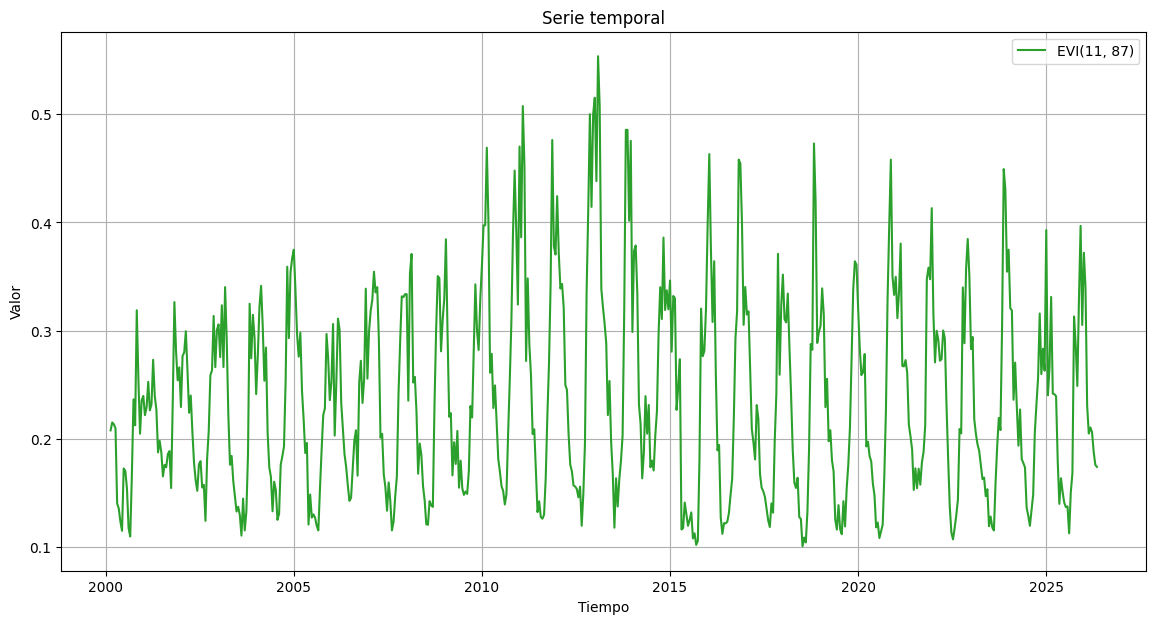

In [3]:
s = Serie(valores, t, "EVI(11, 87)")
s.dibujo(ancho=14)

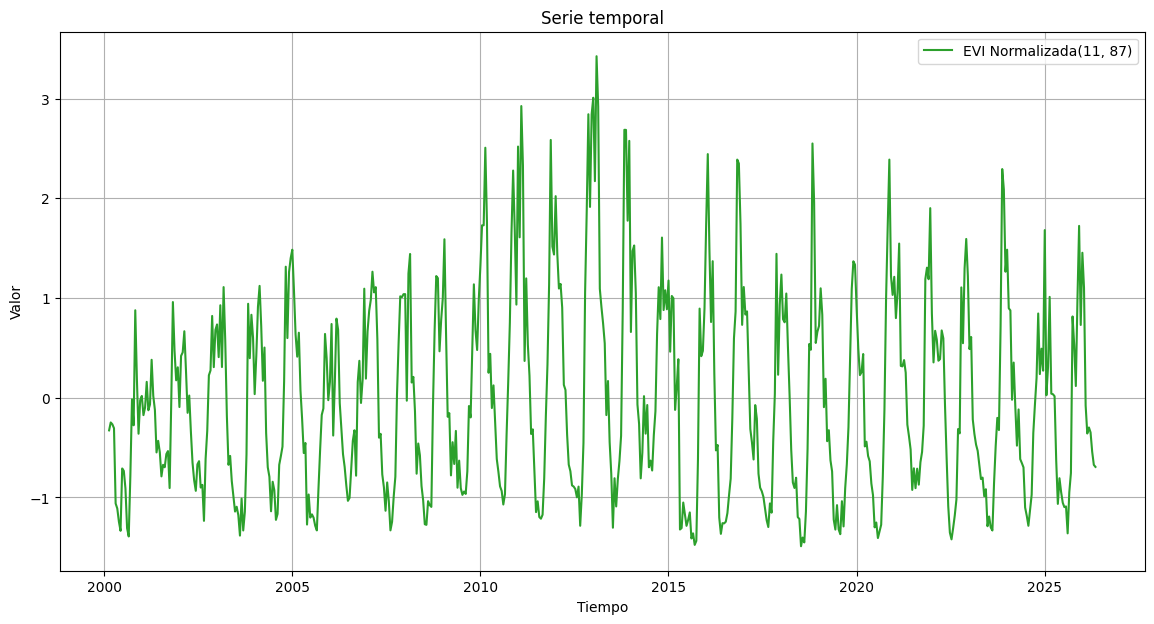

In [4]:
s = Serie((valores-valores.mean())/valores.std(), t, "EVI Normalizada(11, 87)")
s.dibujo(ancho=14)

### ACF y PACF

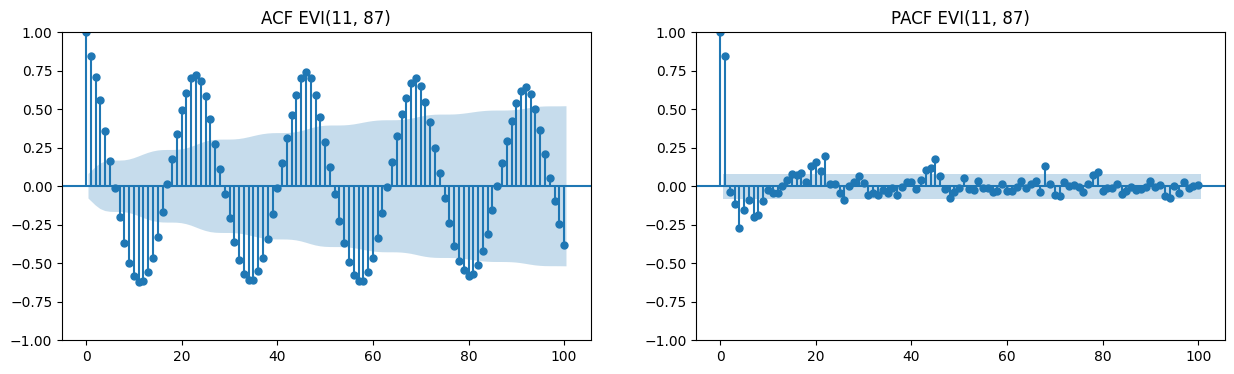

In [5]:
autocorrelacion = Autocorrelacion(t, valores, "EVI(11, 87)")
autocorrelacion.grafico()

In [6]:
acf = np.array(autocorrelacion.acf())
peaks = np.where((acf[1:-1] > acf[:-2]) & (acf[1:-1] > acf[2:]))[0] + 1
peaks

array([23, 46, 69, 92])

In [7]:
autocorrelacion.pacf_significativos()

[(1, np.float64(0.847)),
 (3, np.float64(-0.113)),
 (4, np.float64(-0.273)),
 (5, np.float64(-0.151)),
 (6, np.float64(-0.089)),
 (7, np.float64(-0.197)),
 (8, np.float64(-0.19)),
 (9, np.float64(-0.098)),
 (17, np.float64(0.088)),
 (19, np.float64(0.132)),
 (20, np.float64(0.158)),
 (21, np.float64(0.097)),
 (22, np.float64(0.199)),
 (26, np.float64(-0.089)),
 (43, np.float64(0.105)),
 (44, np.float64(0.118)),
 (45, np.float64(0.177)),
 (68, np.float64(0.133)),
 (79, np.float64(0.094))]

In [20]:
print("NaN valores", any(np.isnan(valores)))
print("NaN t", any(np.isnan(t)))

NaN valores False
NaN t False


## Ajuste con Procesos Gaussianos

In [21]:

b_serie = valores
t_serie = t

ajuste = Ajuste(b_serie, t_serie, 24)
modelos =ajuste.evaluar_modelos()

Ajustando modelo con kernel: 1**2 * RBF(length_scale=0.3) + WhiteKernel(noise_level=0.1)
RBF                   RMSE=0.07528  cobertura=100.0%  logML=-444.24  k=3  AIC=894.49
   0.906**2 * RBF(length_scale=0.135) + WhiteKernel(noise_level=0.117)
Ajustando modelo con kernel: 1**2 * Matern(length_scale=0.3, nu=1.5) + WhiteKernel(noise_level=0.1)
Matérn 3/2            RMSE=0.07366  cobertura=100.0%  logML=-439.81  k=3  AIC=885.61
   0.998**2 * Matern(length_scale=0.207, nu=1.5) + WhiteKernel(noise_level=0.0937)
Ajustando modelo con kernel: 1**2 * RationalQuadratic(alpha=1, length_scale=0.3) + WhiteKernel(noise_level=0.1)
RationalQuadratic     RMSE=0.07441  cobertura=100.0%  logML=-441.27  k=4  AIC=890.55
   0.943**2 * RationalQuadratic(alpha=3.3, length_scale=0.14) + WhiteKernel(noise_level=0.111)
Ajustando modelo con kernel: 1**2 * ExpSineSquared(length_scale=1, periodicity=1) + WhiteKernel(noise_level=0.1)


/home/nadia/unsl/series/sandbox/.venv/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 0.05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/nadia/unsl/series/sandbox/.venv/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__periodicity is close to the specified lower bound 0.5. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/nadia/unsl/series/sandbox/.venv/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified upper bound 0.25. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


Periódico Puro        RMSE=0.04715  cobertura=91.7%  logML=-529.38  k=4  AIC=1066.77
   0.789**2 * ExpSineSquared(length_scale=0.05, periodicity=0.5) + WhiteKernel(noise_level=0.25)
Ajustando modelo con kernel: 1**2 * ExpSineSquared(length_scale=1, periodicity=1) + 1**2 * Matern(length_scale=0.3, nu=1.5) + WhiteKernel(noise_level=0.1)
Periódico + Matérn    RMSE=0.04976  cobertura=91.7%  logML=-349.33  k=6  AIC=710.65
   0.687**2 * ExpSineSquared(length_scale=0.502, periodicity=1) + 0.468**2 * Matern(length_scale=0.154, nu=1.5) + WhiteKernel(noise_level=0.0946)


### Gráficos de los Modelos

RBF (np.float64(0.07528198180179138), np.float64(1.0), np.float64(894.4853208266346))
Matérn 3/2 (np.float64(0.07365714449437073), np.float64(1.0), np.float64(885.6117674214353))
RationalQuadratic (np.float64(0.07441338986032178), np.float64(1.0), np.float64(890.5456858006776))
Periódico Puro (np.float64(0.0471510730298172), np.float64(0.9166666666666666), np.float64(1066.7681639109942))
Periódico + Matérn (np.float64(0.04975667227483712), np.float64(0.9166666666666666), np.float64(710.6511033188725))


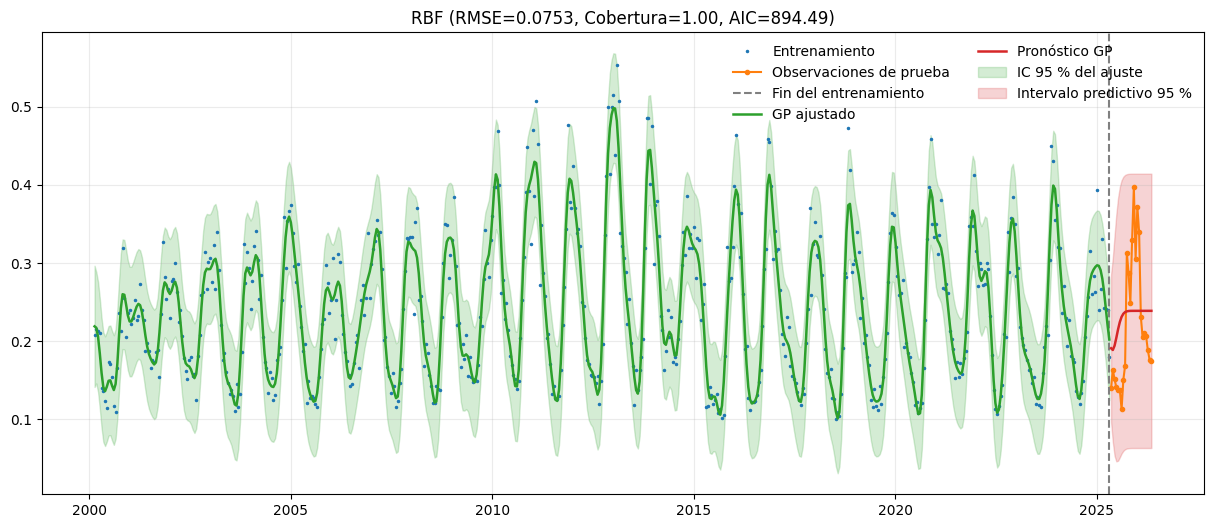

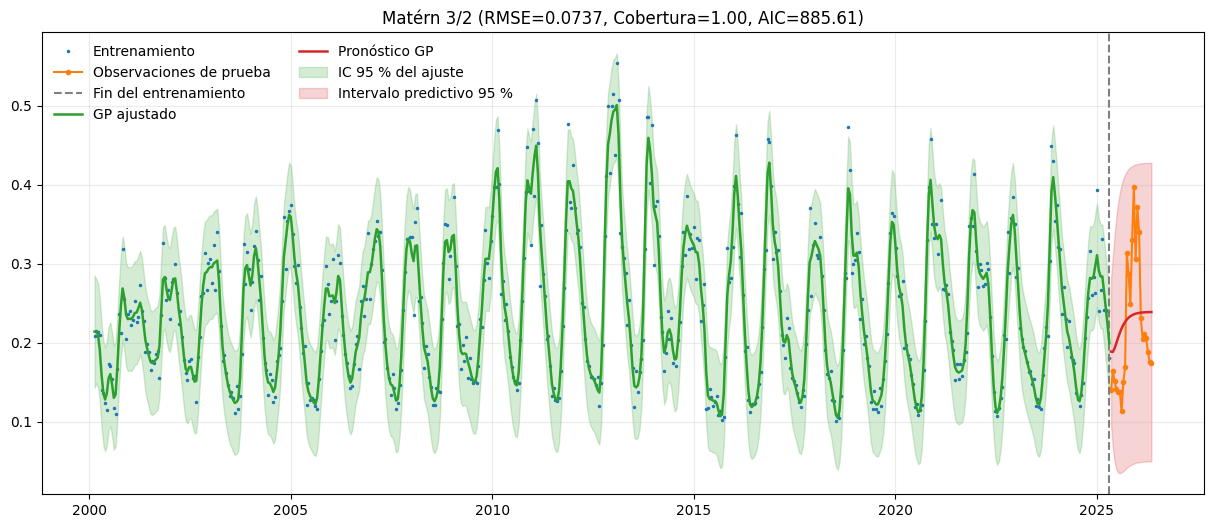

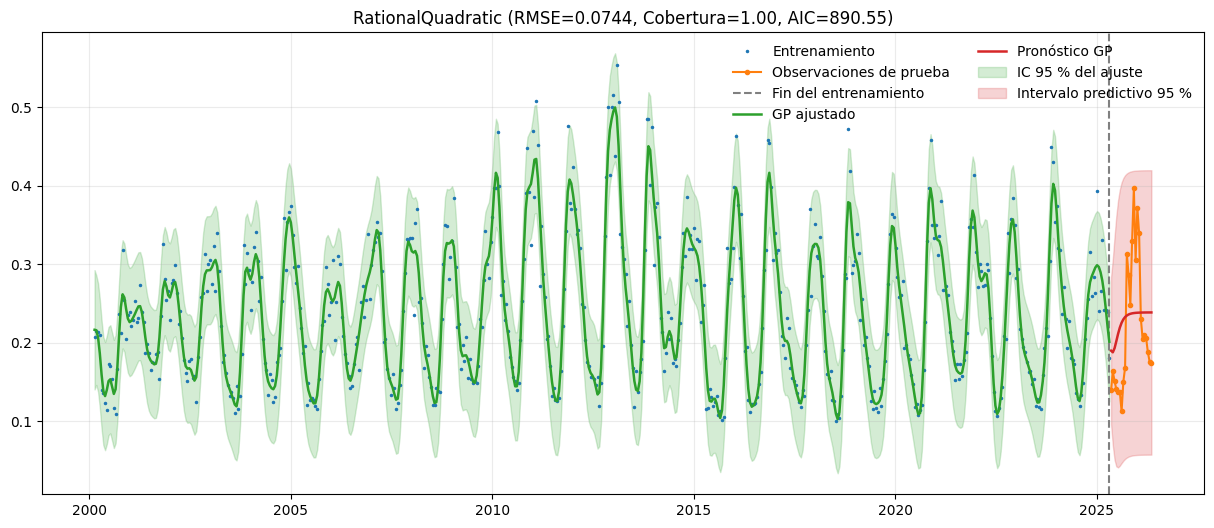

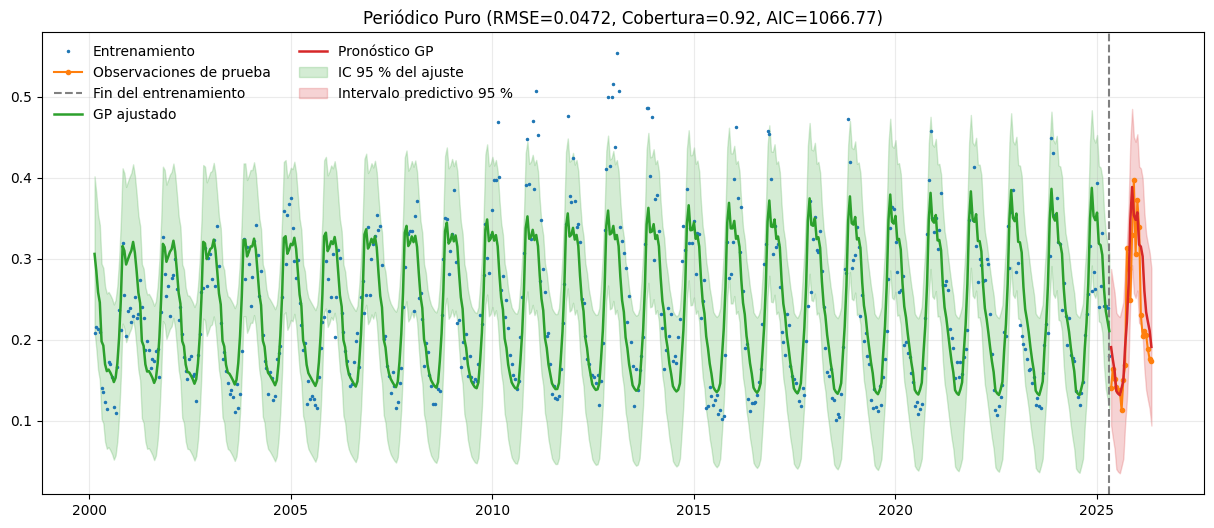

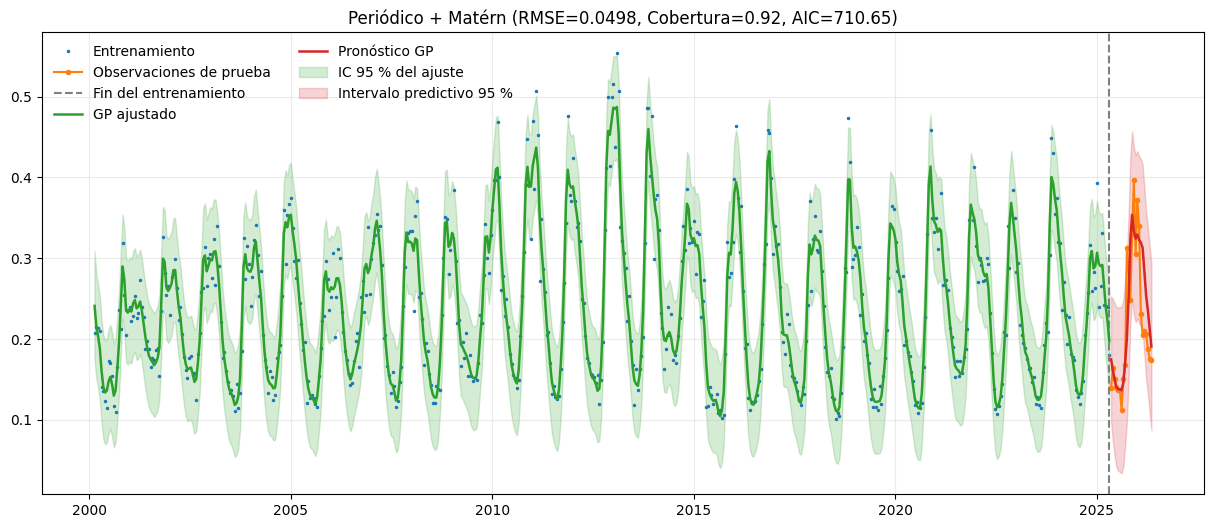

In [9]:
for i, nombre in enumerate(modelos):
    print(nombre, modelos[nombre][3:])
    fig, ax = plt.subplots(1, 1, figsize=(15, 6))
    ajuste.dibujo(modelos[nombre][0], ax=ax, title=f"{nombre} (RMSE={modelos[nombre][3]:.4f}, Cobertura={modelos[nombre][4]:.2f}, AIC={modelos[nombre][5]:.2f})")

In [10]:
df = ajuste.validacion_kernels()

Ajustando modelo con kernel: 1**2 * RBF(length_scale=0.3) + WhiteKernel(noise_level=0.1)
Ajustando modelo con kernel: 1**2 * RBF(length_scale=0.3) + WhiteKernel(noise_level=0.1)
Ajustando modelo con kernel: 1**2 * RBF(length_scale=0.3) + WhiteKernel(noise_level=0.1)
Ajustando modelo con kernel: 1**2 * Matern(length_scale=0.3, nu=1.5) + WhiteKernel(noise_level=0.1)
Ajustando modelo con kernel: 1**2 * Matern(length_scale=0.3, nu=1.5) + WhiteKernel(noise_level=0.1)


/home/nadia/unsl/series/sandbox/.venv/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k1__constant_value is close to the specified upper bound 1.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/nadia/unsl/series/sandbox/.venv/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k1__constant_value is close to the specified upper bound 1.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


Ajustando modelo con kernel: 1**2 * Matern(length_scale=0.3, nu=1.5) + WhiteKernel(noise_level=0.1)
Ajustando modelo con kernel: 1**2 * RationalQuadratic(alpha=1, length_scale=0.3) + WhiteKernel(noise_level=0.1)
Ajustando modelo con kernel: 1**2 * RationalQuadratic(alpha=1, length_scale=0.3) + WhiteKernel(noise_level=0.1)
Ajustando modelo con kernel: 1**2 * RationalQuadratic(alpha=1, length_scale=0.3) + WhiteKernel(noise_level=0.1)
Ajustando modelo con kernel: 1**2 * ExpSineSquared(length_scale=1, periodicity=1) + WhiteKernel(noise_level=0.1)
Ajustando modelo con kernel: 1**2 * ExpSineSquared(length_scale=1, periodicity=1) + WhiteKernel(noise_level=0.1)
Ajustando modelo con kernel: 1**2 * ExpSineSquared(length_scale=1, periodicity=1) + WhiteKernel(noise_level=0.1)


/home/nadia/unsl/series/sandbox/.venv/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 0.05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/nadia/unsl/series/sandbox/.venv/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__periodicity is close to the specified lower bound 0.5. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/nadia/unsl/series/sandbox/.venv/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified upper bound 0.25. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/nadia/un

Ajustando modelo con kernel: 1**2 * ExpSineSquared(length_scale=1, periodicity=1) + 1**2 * Matern(length_scale=0.3, nu=1.5) + WhiteKernel(noise_level=0.1)
Ajustando modelo con kernel: 1**2 * ExpSineSquared(length_scale=1, periodicity=1) + 1**2 * Matern(length_scale=0.3, nu=1.5) + WhiteKernel(noise_level=0.1)
Ajustando modelo con kernel: 1**2 * ExpSineSquared(length_scale=1, periodicity=1) + 1**2 * Matern(length_scale=0.3, nu=1.5) + WhiteKernel(noise_level=0.1)


/home/nadia/unsl/series/sandbox/.venv/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k1__k1__constant_value is close to the specified upper bound 1.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


#### Evaluación de los Modelo con Ventana Deslizante

In [22]:

df.groupby('kernel')["error^2"].mean().transform(np.sqrt).sort_values(ascending=True)

kernel
Periódico Puro        0.042399
Periódico + Matérn    0.044652
RBF                   0.076380
RationalQuadratic     0.079172
Matérn 3/2            0.082385
Name: error^2, dtype: float64

## Residuos
### Kernel Periódico + Matérn
#### Residuos Entrenamiento

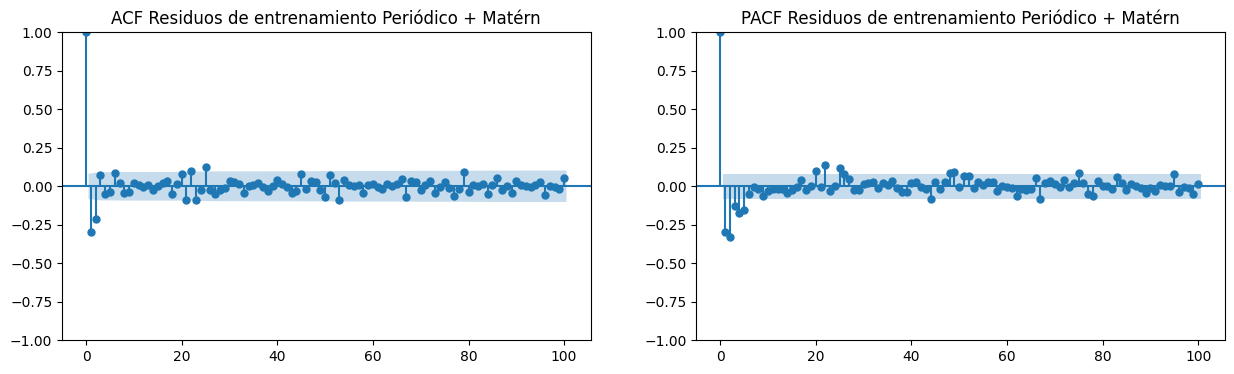

In [12]:
media_entrenamiento, _,media_prueba,_ = ajuste.estimacion(modelos["Periódico + Matérn"][0], ajuste.t_entrenamiento, ajuste.b_entrenamiento, ajuste.t_prueba)
Autocorrelacion(ajuste.t_entrenamiento, ajuste.b_entrenamiento - media_entrenamiento, "Residuos de entrenamiento Periódico + Matérn").grafico()

#### Residuos Prueba

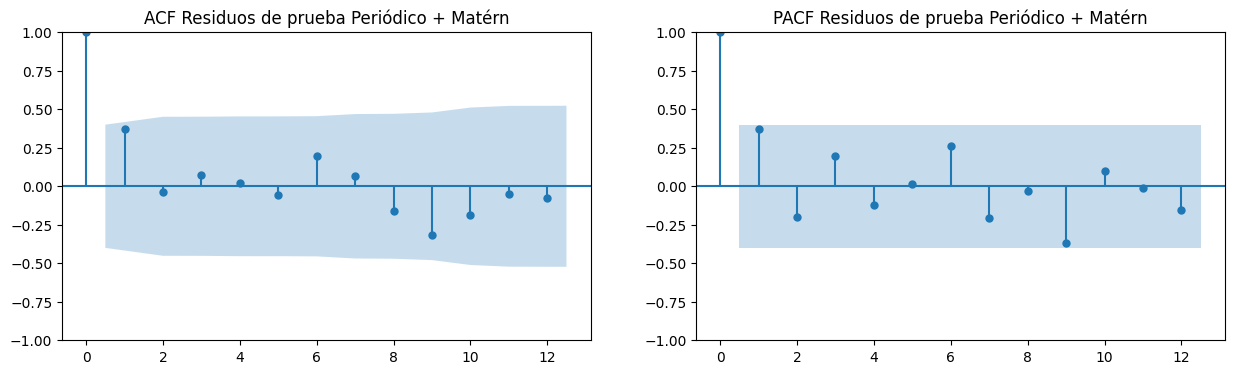

In [13]:
Autocorrelacion(ajuste.t_prueba, ajuste.b_prueba - media_prueba, "Residuos de prueba Periódico + Matérn").grafico(lags=12)

### Kernel Periódico Puro
#### Residuos Entrenamiento

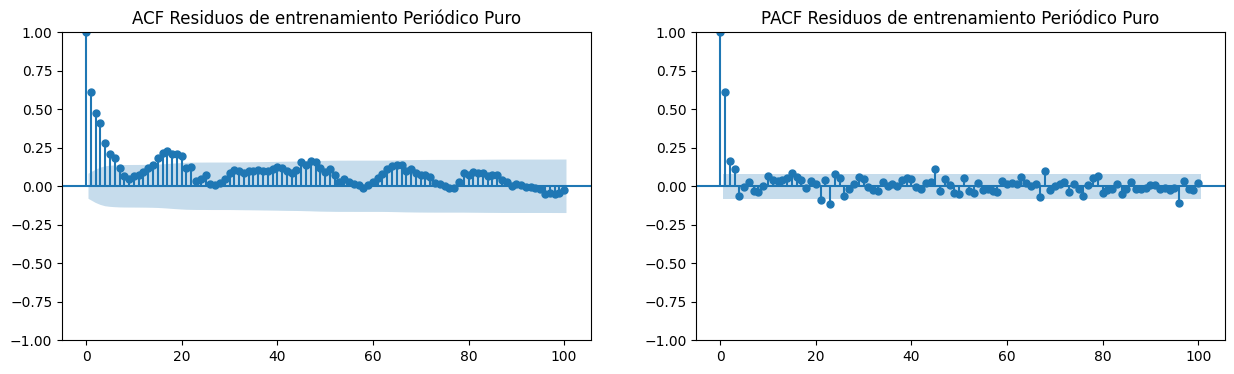

In [14]:
media_entrenamiento, _,media_prueba,_ = ajuste.estimacion(modelos["Periódico Puro"][0], ajuste.t_entrenamiento, ajuste.b_entrenamiento, ajuste.t_prueba)
Autocorrelacion(ajuste.t_entrenamiento, ajuste.b_entrenamiento - media_entrenamiento, "Residuos de entrenamiento Periódico Puro").grafico()

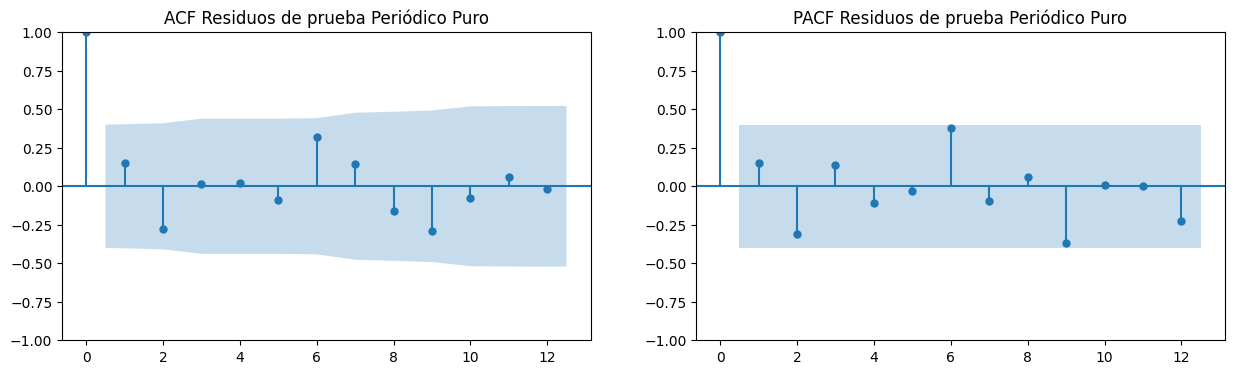

In [15]:
Autocorrelacion(ajuste.t_prueba, ajuste.b_prueba - media_prueba, "Residuos de prueba Periódico Puro").grafico(lags=12)